##Step 1: data generation


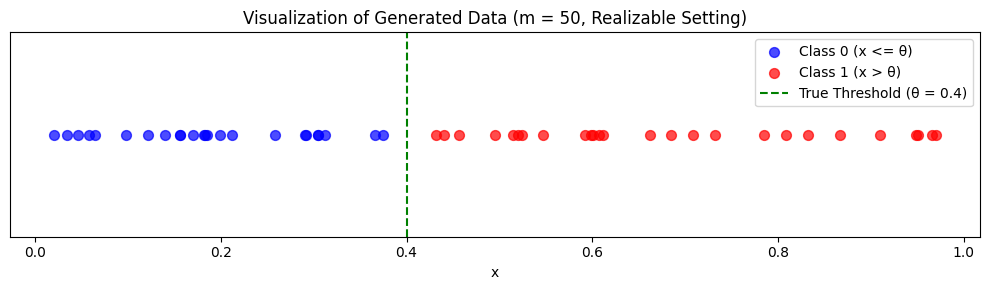

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

def generate_data(m, theta=0.4, eta=0.0):
    """
    Generates m data points.

    Parameters:
    - m: number of samples
    - theta: target threshold parameter in (0, 1)
    - eta: label noise rate in [0, 0.5)

    Returns:
    - X: array of m uniform samples in [0, 1]
    - y: array of m labels in {0, 1}
    """
    # Sample m points uniformly from [0, 1]
    X = np.random.uniform(0, 1, size=m)

    # Realizable labels
    y = (X > theta).astype(int)

    # Introduce label noise if eta > 0
    if eta > 0:
        # Flip labels independently with probability eta
        flip_mask = np.random.rand(m) < eta
        y[flip_mask] = 1 - y[flip_mask]

    return X, y

# Generate datasets for the required sample sizes m
sample_sizes = [5, 10, 20, 50, 100, 200]
target_theta = 0.4

# Generate and inspect one dataset (m = 50)
X_example, y_example = generate_data(m=50, theta=target_theta)

# Visualization
plt.figure(figsize=(10, 3))
plt.scatter(X_example[y_example == 0], np.zeros_like(X_example[y_example == 0]),
            color='blue', label='Class 0 (x <= θ)', alpha=0.7, s=50)
plt.scatter(X_example[y_example == 1], np.zeros_like(X_example[y_example == 1]),
            color='red', label='Class 1 (x > θ)', alpha=0.7, s=50)
plt.axvline(x=target_theta, color='green', linestyle='--', label=f'True Threshold (θ = {target_theta})')

plt.yticks([])
plt.xlabel('x')
plt.title('Visualization of Generated Data (m = 50, Realizable Setting)')
plt.legend()
plt.tight_layout()
plt.show()

##Step2: ERM
To find the optimal threshold $\hat{\theta}$, we first sort our sample points to divide the domain $[0, 1]$ into $m+1$ discrete intervals. We then test candidate thresholds placed at the midpoints between adjacent points, along with the boundary points $0$ and $1$. \
The empirical error $L_S(\hat{\theta})$ remains constant throughout any given interval $(x_{(i)}, x_{(i+1)})$ because any threshold chosen inside it yields identical predictions for every training sample. Therefore, evaluating just the midpoint $\frac{x_{(i)} + x_{(i+1)}}{2}$ for each interval guarantees an exact, exhaustive search over all possible candidate rules.

In [6]:
def compute_empirical_risk(X, y, candidate_theta):
    """
    Computes empirical risk (training error rate) for a given candidate threshold.
    Predicts 1 if x > candidate_theta else 0.
    """
    predictions = (X > candidate_theta).astype(int)
    # Fraction of misclassified samples
    error_rate = np.mean(predictions != y)
    return error_rate

def train_erm(X, y):
    """
    Empirical Risk Minimization for a threshold classifier.
    Returns the threshold theta_hat that minimizes empirical error.
    """
    m = len(X)
    sorted_X = np.sort(X)

    # 1. Generate candidate thresholds (midpoints + boundaries)
    candidates = [0.0]
    for i in range(m - 1):
        midpoint = (sorted_X[i] + sorted_X[i + 1]) / 2.0
        candidates.append(midpoint)
    candidates.append(1.0)

    best_theta = candidates[0]
    best_error = 1.0  # Start with worst possible error

    # 2. Evaluate empirical error for each candidate
    for candidate in candidates:
        err = compute_empirical_risk(X, y, candidate)
        if err < best_error:
            best_error = err
            best_theta = candidate

    return best_theta, best_error

# Quick check on a generated dataset
X_tr, y_tr = generate_data(m=20, theta=0.4)
theta_hat, erm_error = train_erm(X_tr, y_tr)

print(f"True Threshold: 0.4")
print(f"Learned Threshold (θ_hat): {theta_hat:.4f}")
print(f"Empirical Error (L_S): {erm_error:.4f}")

True Threshold: 0.4
Learned Threshold (θ_hat): 0.4292
Empirical Error (L_S): 0.0000


## 3. Performance Evaluation
* Evaluate empirical error $L_S(h)$ on training sets.
* Compute true error $L_D(h)$ using a large independent test set ($M_{\text{test}} \ge 10{,}000$).
* **Output:** Plot comparing $L_S(h)$ vs. $L_D(h)$ across sample sizes $m$.


m =   5 | Empirical Error (L_S): 0.0000 | True Error (L_D): 0.0723 | θ_hat: 0.4697
m =  10 | Empirical Error (L_S): 0.0000 | True Error (L_D): 0.0413 | θ_hat: 0.3581
m =  20 | Empirical Error (L_S): 0.0000 | True Error (L_D): 0.0001 | θ_hat: 0.3998
m =  50 | Empirical Error (L_S): 0.0000 | True Error (L_D): 0.0310 | θ_hat: 0.4290
m = 100 | Empirical Error (L_S): 0.0000 | True Error (L_D): 0.0032 | θ_hat: 0.3973
m = 200 | Empirical Error (L_S): 0.0000 | True Error (L_D): 0.0041 | θ_hat: 0.4037


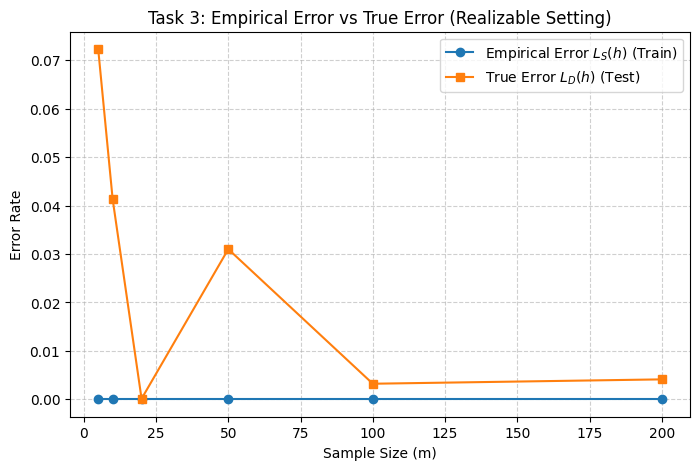

In [3]:
# 1. Generate a large independent test set (Realizable setting, no noise)
M_test = 10000
X_test, y_test = generate_data(m=M_test, theta=target_theta, eta=0.0)

sample_sizes = [5, 10, 20, 50, 100, 200]
empirical_errors = []
true_errors = []

# 2. For each sample size m, train model and evaluate both errors
for m in sample_sizes:
    # Generate training data
    X_train, y_train = generate_data(m=m, theta=target_theta, eta=0.0)

    # Train ERM model
    theta_hat, L_S = train_erm(X_train, y_train)

    # Compute True Error on test set
    L_D = compute_empirical_risk(X_test, y_test, theta_hat)

    empirical_errors.append(L_S)
    true_errors.append(L_D)

    print(f"m = {m:3d} | Empirical Error (L_S): {L_S:.4f} | True Error (L_D): {L_D:.4f} | θ_hat: {theta_hat:.4f}")

# 3. Plot comparison
plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, empirical_errors, marker='o', label='Empirical Error $L_S(h)$ (Train)')
plt.plot(sample_sizes, true_errors, marker='s', label='True Error $L_D(h)$ (Test)')
plt.xlabel('Sample Size (m)')
plt.ylabel('Error Rate')
plt.title('Task 3: Empirical Error vs True Error (Realizable Setting)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Step 4: Experimental Verification of PAC Learning
To experimentally verify the PAC learning, we run $N = 500$ independent repetitions for each sample size $m$ and estimate the failure probability $\mathbb{P}(L_D(h) > \epsilon)$ for a fixed tolerance threshold $\epsilon = 0.05$

m =   5 | Pr(L_D > 0.05) = 0.6000
m =  10 | Pr(L_D > 0.05) = 0.3620
m =  20 | Pr(L_D > 0.05) = 0.1320
m =  50 | Pr(L_D > 0.05) = 0.0120
m = 100 | Pr(L_D > 0.05) = 0.0000
m = 200 | Pr(L_D > 0.05) = 0.0000


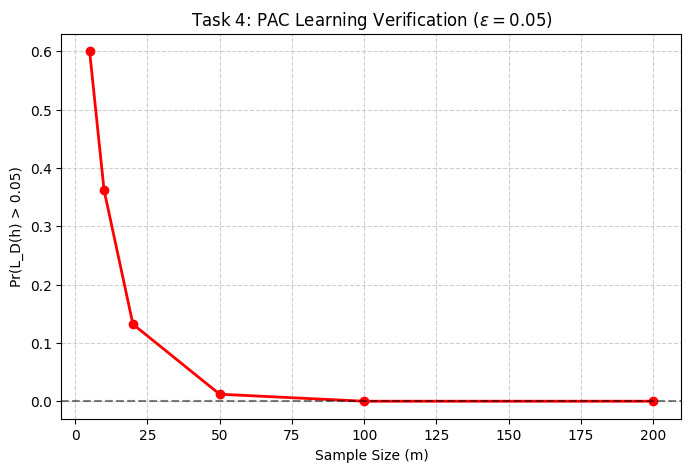

In [4]:
# Parameters for PAC verification
epsilon = 0.05          # Accuracy tolerance (5% error)
num_repetitions = 500   # Number of experimental repetitions (N)
sample_sizes = [5, 10, 20, 50, 100, 200]

failure_probabilities = []

# Generate a large test set to evaluate true error L_D
M_test = 10000
X_test, y_test = generate_data(m=M_test, theta=target_theta, eta=0.0)

for m in sample_sizes:
    failures = 0

    for _ in range(num_repetitions):
        # 1. Generate new training dataset of size m
        X_train, y_train = generate_data(m=m, theta=target_theta, eta=0.0)

        # 2. Train ERM model
        theta_hat, _ = train_erm(X_train, y_train)

        # 3. Compute true error L_D
        L_D = compute_empirical_risk(X_test, y_test, theta_hat)

        # 4. Check if trial failed (L_D > epsilon)
        if L_D > epsilon:
            failures += 1

    # Estimate failure probability Pr(L_D > epsilon)
    prob_failure = failures / num_repetitions
    failure_probabilities.append(prob_failure)
    print(f"m = {m:3d} | Pr(L_D > {epsilon}) = {prob_failure:.4f}")

# Plot failure probability vs sample size
plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, failure_probabilities, marker='o', color='red', linewidth=2)
plt.axhline(y=0.0, color='black', linestyle='--', alpha=0.5)
plt.xlabel('Sample Size (m)')
plt.ylabel(f'Pr(L_D(h) > {epsilon})')
plt.title(rf'Task 4: PAC Learning Verification ($\epsilon = {epsilon}$)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Conclusion: As the training size $m$ increases, the probability of obtaining a threshold with true error greater than $\epsilon$ drops sharply toward $0$.

## Step 5: From PAC to Agnostic PAC (Label Noise)
In this section, we introduce label noise ($\eta = 0.15$) to transition from the realizable PAC setting to the Agnostic PAC setting

<>:43: SyntaxWarning: invalid escape sequence '\e'
<>:43: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_900/1974695524.py:43: SyntaxWarning: invalid escape sequence '\e'
  ax1.set_title('Task 5: Error Rates with Label Noise ($\eta = 0.15$)')


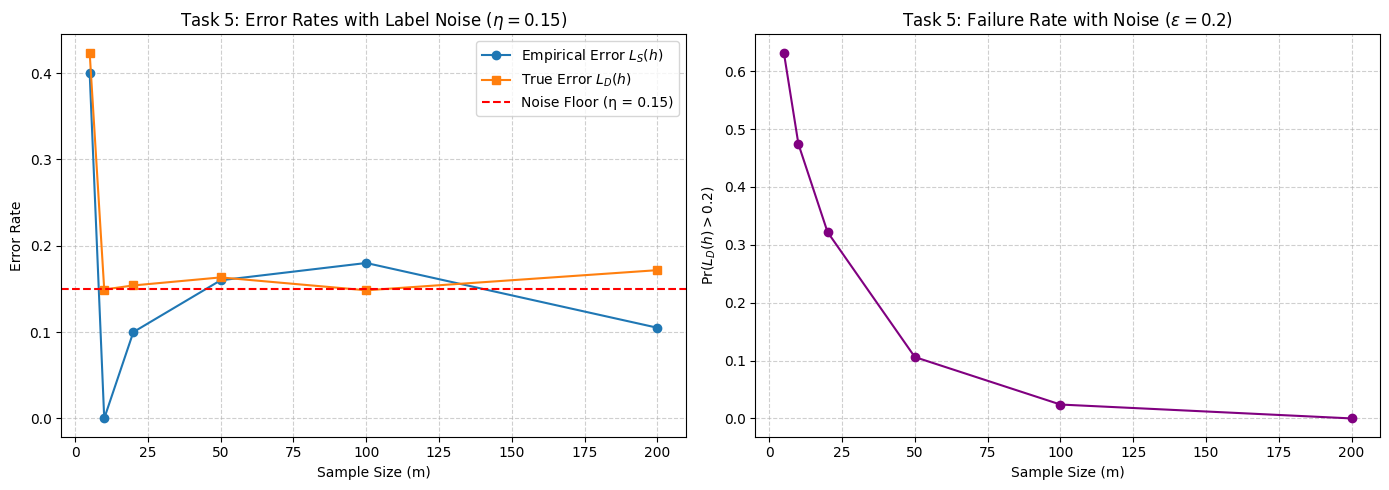

In [5]:
# Parameters for Agnostic PAC setting
eta = 0.15              # 15% label noise
epsilon_agnostic = 0.20 # Higher threshold since irreducible noise = 0.15
num_repetitions = 500
sample_sizes = [5, 10, 20, 50, 100, 200]

# Generate noisy test set (10,000 samples)
M_test = 10000
X_test_noisy, y_test_noisy = generate_data(m=M_test, theta=target_theta, eta=eta)

agnostic_empirical_errors = []
agnostic_true_errors = []
agnostic_failure_probs = []

for m in sample_sizes:
    # --- Part 1: Single run performance evaluation ---
    X_train_noisy, y_train_noisy = generate_data(m=m, theta=target_theta, eta=eta)
    theta_hat_noisy, L_S_noisy = train_erm(X_train_noisy, y_train_noisy)
    L_D_noisy = compute_empirical_risk(X_test_noisy, y_test_noisy, theta_hat_noisy)

    agnostic_empirical_errors.append(L_S_noisy)
    agnostic_true_errors.append(L_D_noisy)

    # --- Part 2: Repetitions for failure probability ---
    failures = 0
    for _ in range(num_repetitions):
        X_tr, y_tr = generate_data(m=m, theta=target_theta, eta=eta)
        t_hat, _ = train_erm(X_tr, y_tr)
        L_D_rep = compute_empirical_risk(X_test_noisy, y_test_noisy, t_hat)
        if L_D_rep > epsilon_agnostic:
            failures += 1

    agnostic_failure_probs.append(failures / num_repetitions)

# Plotting performance evaluation under noise
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(sample_sizes, agnostic_empirical_errors, marker='o', label=r'Empirical Error $L_S(h)$')
ax1.plot(sample_sizes, agnostic_true_errors, marker='s', label=r'True Error $L_D(h)$')
ax1.axhline(y=eta, color='red', linestyle='--', label=f'Noise Floor (η = {eta})')
ax1.set_xlabel('Sample Size (m)')
ax1.set_ylabel('Error Rate')
ax1.set_title('Task 5: Error Rates with Label Noise ($\eta = 0.15$)')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(sample_sizes, agnostic_failure_probs, marker='o', color='purple')
ax2.set_xlabel('Sample Size (m)')
ax2.set_ylabel(rf'Pr($L_D(h) > {epsilon_agnostic}$)')
ax2.set_title(rf'Task 5: Failure Rate with Noise ($\epsilon = {epsilon_agnostic}$)')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

##Discussion & Conclusion

1.   Can the empirical error still reach zero?\
 No. While $L_S(h)$ happens to hit 0 at $m=10$ due to a small sample artifact, as $m$ increases ($m \ge 20$), the empirical error stabilizes around $0.10 - 0.18$. Because labels are randomly flipped with noise $\eta = 0.15$, no single threshold can perfectly separate the classes without making mistakes on larger training sets.


2. Does increasing the number of training examples still improve generalization performance?\
Yes. More training examples reduce variance and stabilize the true error $L_D(h)$. Furthermore, the failure rate $Pr(L_D(h) > 0.20)$ steadily drops from over $60\%$ at $m=5$ down to nearly $0\%$ by $m=200$, showing that larger sample sizes lead to a much more reliable model.  
3.  Relation to PAC vs. Agnostic PAC:

*   PAC: Assumes a target function exists that achieves zero risk ($L_D = 0$). The true error can be bounded arbitrarily close to 0 given enough data.
*   Agnostic PAC: Drops the zero-risk assumption to account for noise ($\eta > 0$). Since zero total error is impossible, Agnostic PAC guarantees that as sample size $m$ increases, ERM finds a threshold whose true error gets arbitrarily close to the best possible error achievable within our hypothesis class ($L_D(h) \approx \min_{h' \in \mathcal{H}} L_D(h') \approx \eta$).
